## Node2Vec:

---

In [1]:
import pickle

with open('../../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [2]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

d:\GitHub\Repositories\Behavioral Homophily Network\behavioral-homophily-network\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Computing transition probabilities: 100%|██████████| 150/150 [00:00<00:00, 189.56it/s]


In [3]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4,
)

In [4]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [5]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [6]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [7]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [8]:
display(vectors_64d)


array([[-0.06945533, -0.1928898 , -0.0386379 , ..., -0.11218911,
        -0.06066049,  0.1542489 ],
       [ 0.19360156, -0.11596096,  0.12747017, ..., -0.18110172,
         0.17525923, -0.01526612],
       [-0.15790312, -0.19401759,  0.00271479, ...,  0.12343007,
        -0.15716524,  0.06296267],
       ...,
       [ 0.09003946, -0.28072906,  0.12795597, ..., -0.12867048,
         0.10963933, -0.15824258],
       [-0.11836447, -0.11725995,  0.04231771, ..., -0.03150824,
        -0.0113918 ,  0.27596676],
       [ 0.09182172, -0.20880051,  0.15409726, ..., -0.23322178,
         0.12249992, -0.09021451]], dtype=float32)

In [9]:
# Loading the pyshcological profile labels:

node_labels = np.load('../../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [11]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


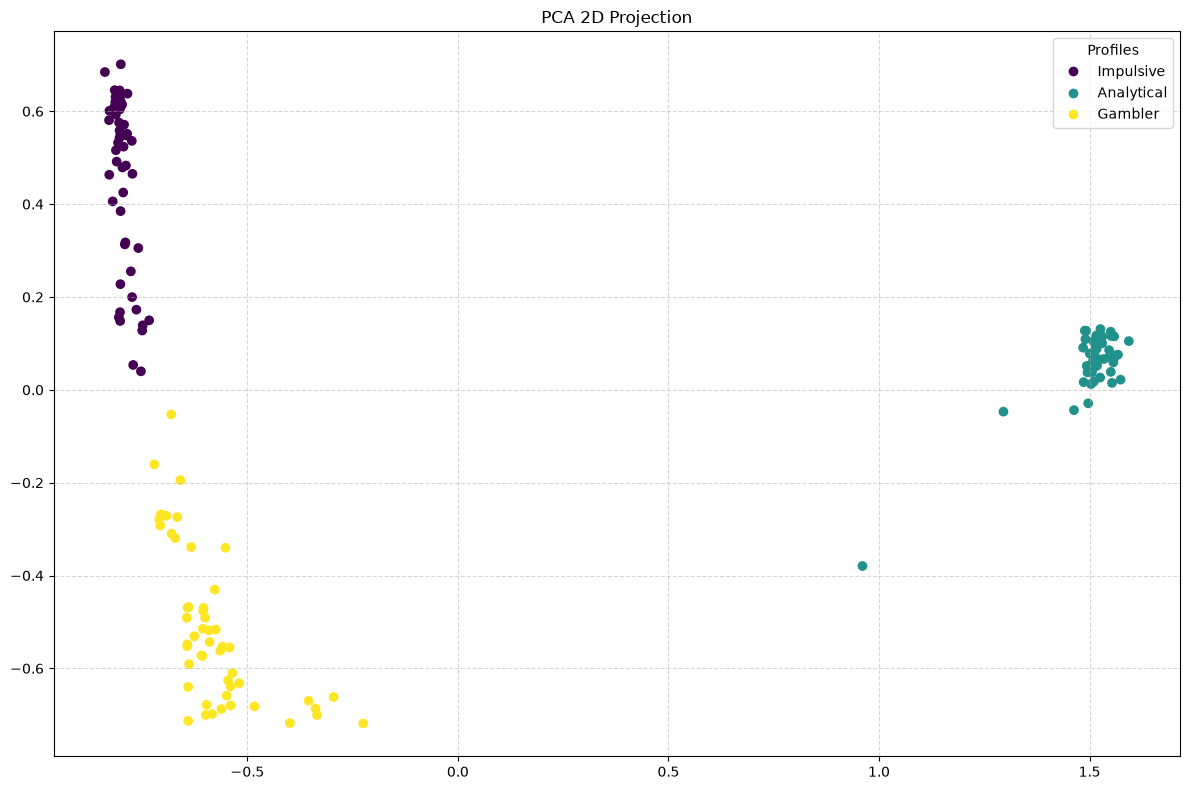

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')

plt.grid(True, linestyle='--', alpha=0.5)

plt.title('PCA 2D Projection')

plt.tight_layout()
plt.savefig('PCA-Projection.png', dpi=300)
plt.show()

---

### t-SNE:

In [15]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    max_iter=1000, 
    random_state=42
)

In [16]:
vectors_tsne = tsne.fit_transform(vectors_64d)

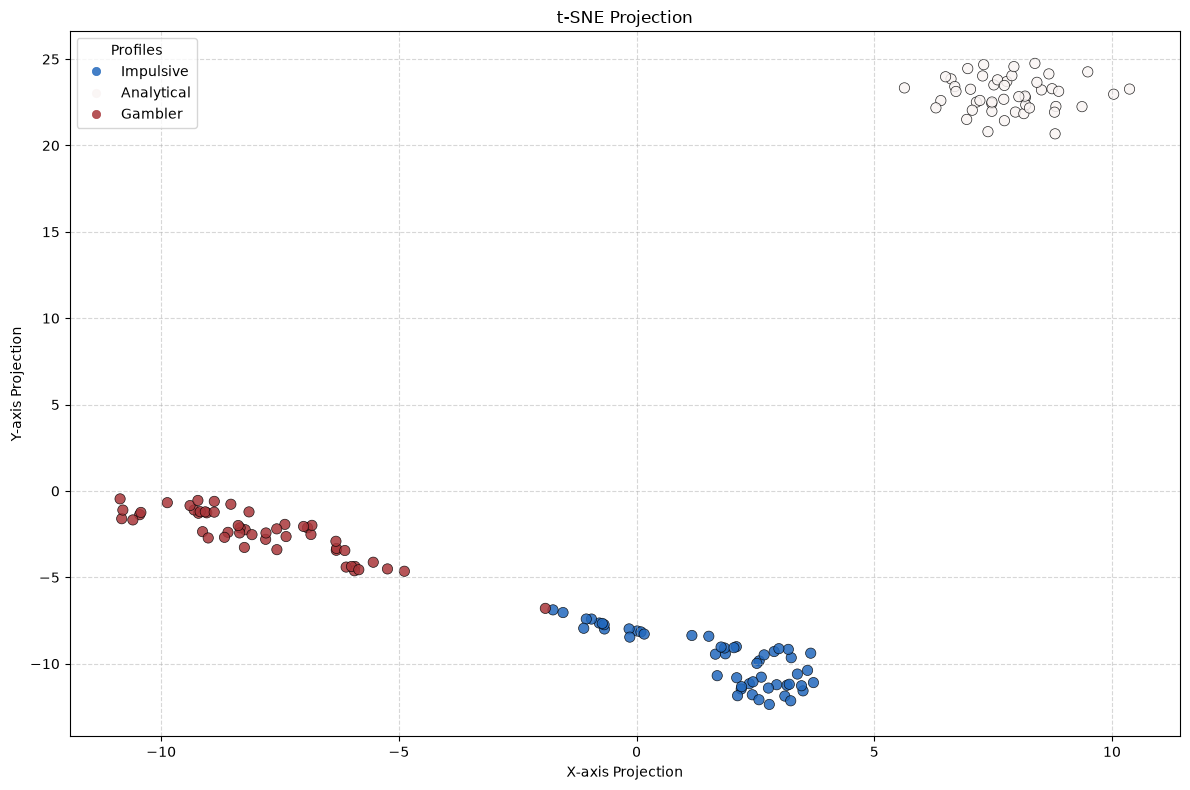

In [17]:
import seaborn as sns

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    vectors_tsne[:, 0], 
    vectors_tsne[:, 1], 
    c=node_labels, 
    cmap='vlag',  
    alpha=0.85, 
    s=55, 
    edgecolors='k',
    linewidth=0.5
)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')

plt.grid(True, linestyle='--', alpha=0.5)

plt.xlabel('X-axis Projection')
plt.ylabel('Y-axis Projection')
plt.title('t-SNE Projection')

plt.tight_layout()
plt.savefig('t-SNE.png', dpi=300)
plt.show()